# Vehicle Speed Prediction - V1.0

Hey, so this is my first attempt at building a classifier for vehicle speed actions. The idea is pretty simple - given some car data like speed, engine temp, fuel level etc., can we predict what "action" the car is doing? Like is it going really fast, fast, normal, slow, or very slow.

I'm using the Decision Tree Classifier here because it's straightforward and easy to understand. In V1.1 I'll try out more models and compare them.

**What I'm working with:**
- 500 rows of synthetic car data
- 8 features (speed, engine_temp, fuel_level, tire_pressure, car_age, weather, driver exp, traffic)
- 5 action classes based on speed thresholds

## Step 1: Importing libraries and loading data

First let me bring in the libraries I need. I'm using pandas for data handling, numpy for numbers, and matplotlib/seaborn for plots.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("Imports done!")

Imports done!


In [2]:
# loading the dataset
df = pd.read_csv('car_speed_data.csv')
print(f"Shape of data: {df.shape}")
print(f"\nFirst 5 rows:")
df.head()

Shape of data: (500, 9)

First 5 rows:


,speed,engine_temp,fuel_level,tire_pressure,car_age,weather_condition,driver_experience,traffic_condition,action
0,9,119.665945,87.230502,33.689042,9,1,2,0,very slow
1,117,66.157384,86.088681,30.290136,4,0,1,0,really fast
2,75,60.628500,18.018498,33.509206,6,0,2,0,normal
3,64,119.782186,63.553022,31.456687,2,1,0,0,normal
4,76,66.681758,97.645855,32.081484,14,1,0,0,normal


## Step 2: Quick look at the data

Before doing anything with the model, I need to understand what this data looks like. Let me check for any missing values and see the basic stats.

In [3]:
# checking for missing values
print("Missing values:")
print(df.isnull().sum())
print(f"\nAny duplicates? {df.duplicated().sum()} rows")

# basic stats
print(f"\nData types:")
print(df.dtypes)
print(f"\nStatistical summary:")
df.describe().round(2)

Missing values:
speed                0
engine_temp          0
fuel_level           0
tire_pressure        0
car_age              0
weather_condition    0
driver_experience    0
traffic_condition    0
action               0
dtype: int64

Any duplicates? 0 rows

Data types:
speed                  int64
engine_temp          float64
fuel_level           float64
tire_pressure        float64
car_age                int64
weather_condition      int64
driver_experience      int64
traffic_condition      int64
action                object
dtype: object

Statistical summary:


,speed,engine_temp,fuel_level,tire_pressure,car_age,weather_condition,driver_experience,traffic_condition
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,61.10,89.54,54.13,32.54,9.77,0.98,1.00,0.99
std,33.82,17.11,25.10,1.43,5.75,0.82,0.82,0.84
min,0.00,60.26,10.75,30.01,0.00,0.00,0.00,0.00
25%,34.00,75.12,32.69,31.35,5.00,0.00,0.00,0.00
50%,59.00,88.46,53.41,32.51,10.00,1.00,1.00,1.00
75%,90.00,103.96,75.46,33.80,15.00,2.00,2.00,2.00
max,119.00,120.00,99.89,34.99,19.00,2.00,2.00,2.00


Action distribution:
action
very slow      208
fast            89
really fast     87
normal          73
slow            43
Name: count, dtype: int64


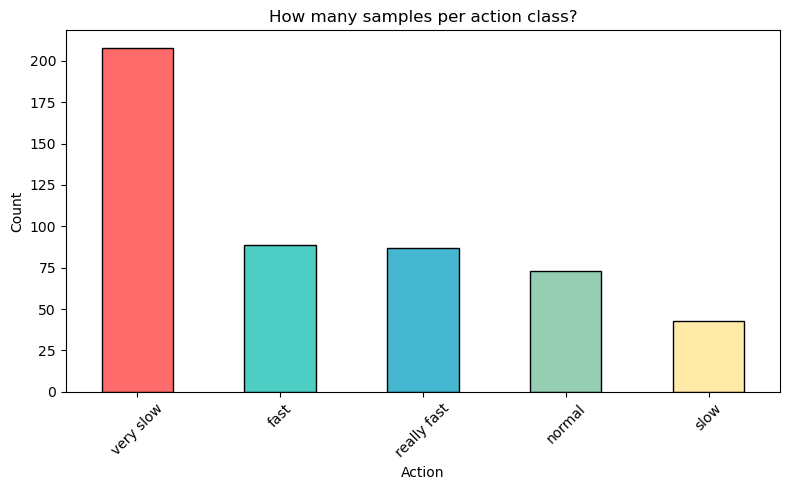

In [4]:
# how many of each action class do we have?
print("Action distribution:")
print(df['action'].value_counts())

# lets visualize this
plt.figure(figsize=(8, 5))
df['action'].value_counts().plot(kind='bar', color=['#ff6b6b', '#4ecdc4', '#45b7d1', '#96ceb4', '#ffeaa7'], edgecolor='black')
plt.title('How many samples per action class?')
plt.xlabel('Action')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 3: Exploring the features

Now let me look at how each feature is distributed and how they relate to the action classes. This helps me understand which features are important.

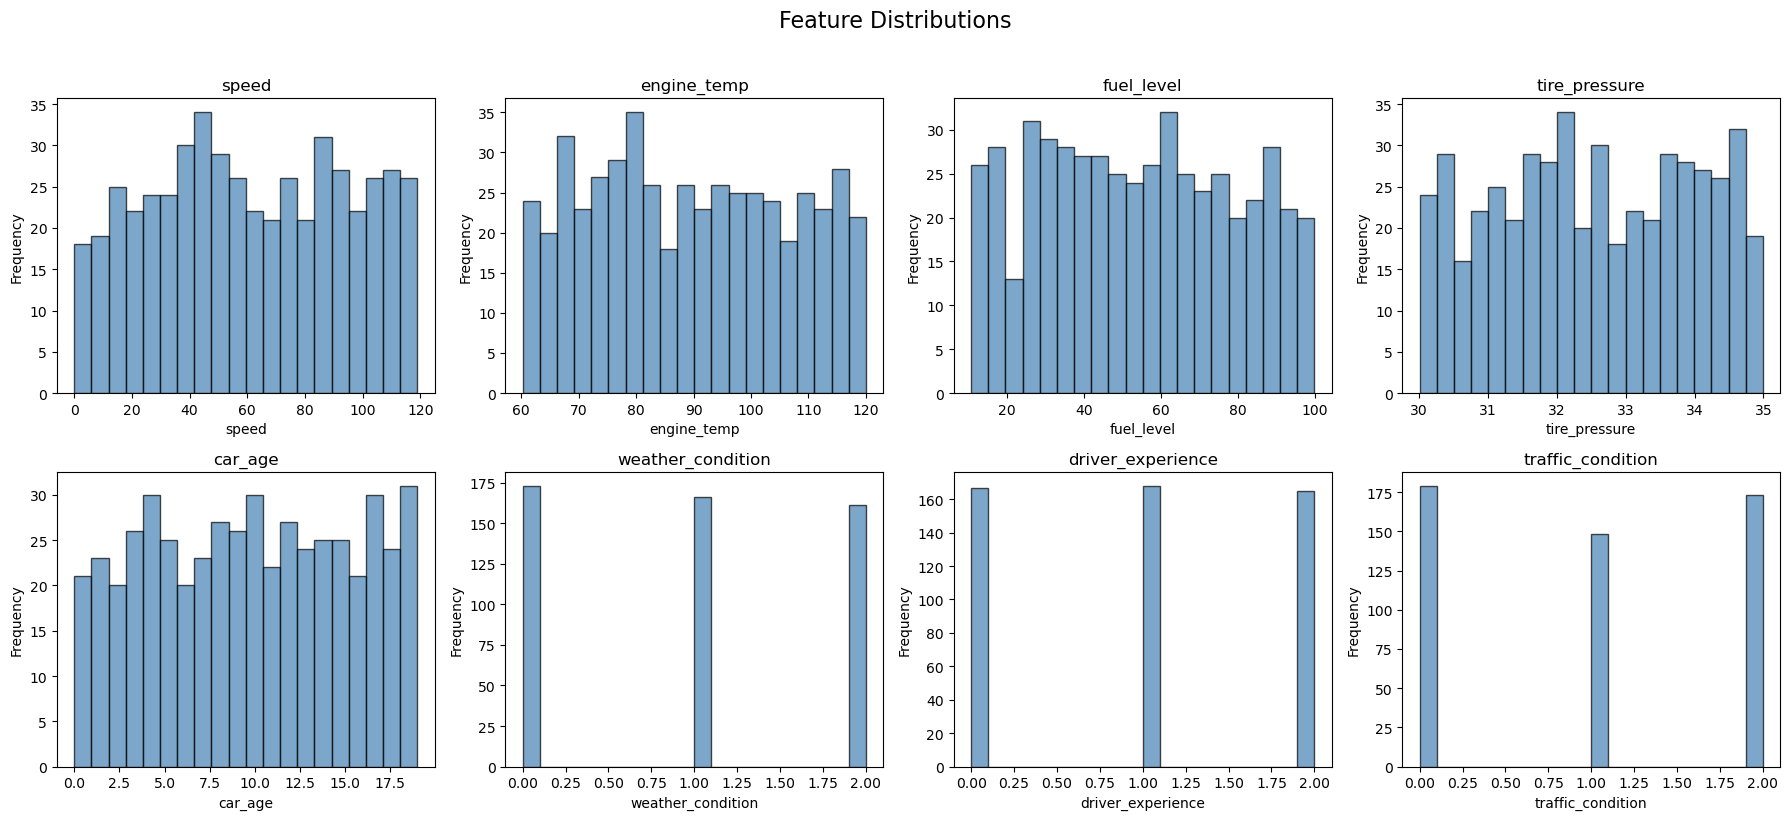

In [5]:
# distribution of each feature
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(df.columns[:-1]):  # skip 'action'
    axes[i].hist(df[col], bins=20, color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

plt.suptitle('Feature Distributions', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

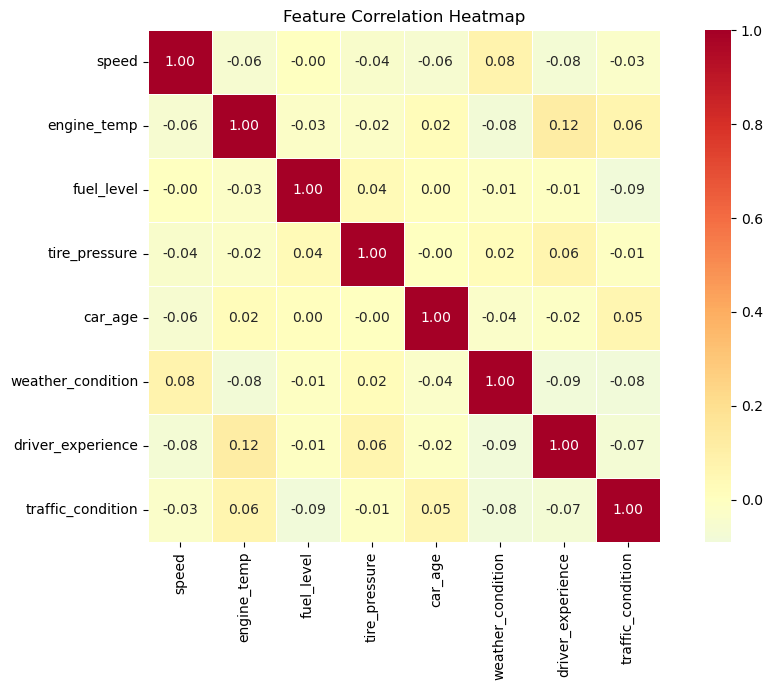

Nothing too surprising here - speed and action are obviously related since we defined the classes based on speed.
The other features are pretty much independent which makes sense for synthetic data.


In [6]:
# correlation heatmap - which features are related to each other?
plt.figure(figsize=(10, 7))
numeric_cols = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='RdYlBu_r', center=0, fmt='.2f',
            square=True, linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

print("Nothing too surprising here - speed and action are obviously related since we defined the classes based on speed.")
print("The other features are pretty much independent which makes sense for synthetic data.")

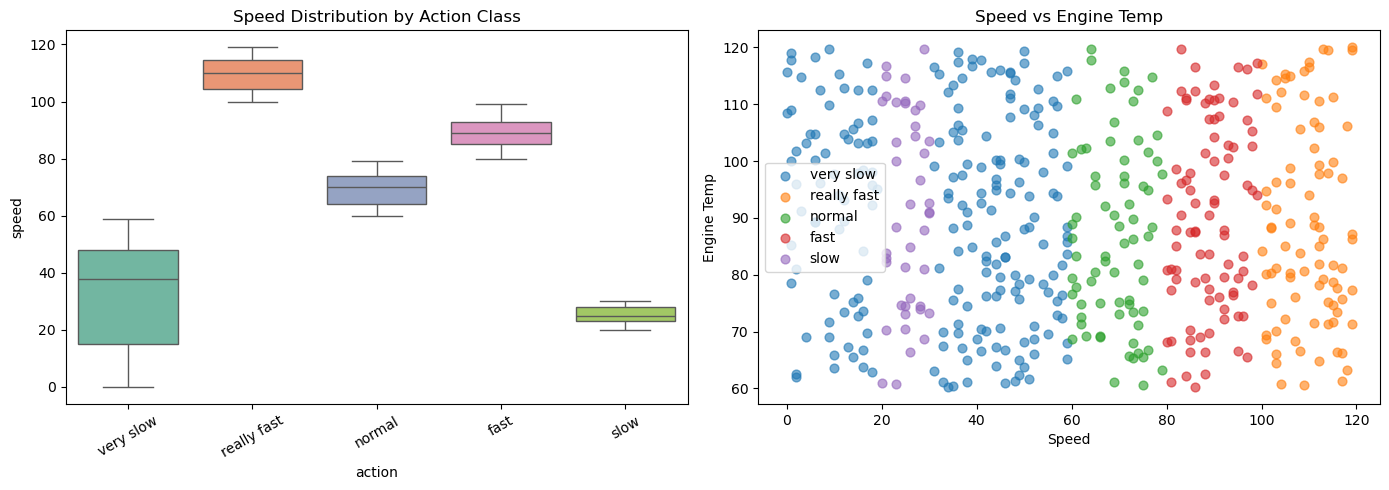

In [7]:
# lets see how speed looks for each action class
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# boxplot of speed by action
sns.boxplot(data=df, x='action', y='speed', palette='Set2', ax=axes[0])
axes[0].set_title('Speed Distribution by Action Class')
axes[0].tick_params(axis='x', rotation=30)

# scatter plot - speed vs engine temp colored by action
for action in df['action'].unique():
    subset = df[df['action'] == action]
    axes[1].scatter(subset['speed'], subset['engine_temp'], label=action, alpha=0.6, s=40)
axes[1].set_xlabel('Speed')
axes[1].set_ylabel('Engine Temp')
axes[1].set_title('Speed vs Engine Temp')
axes[1].legend()

plt.tight_layout()
plt.show()

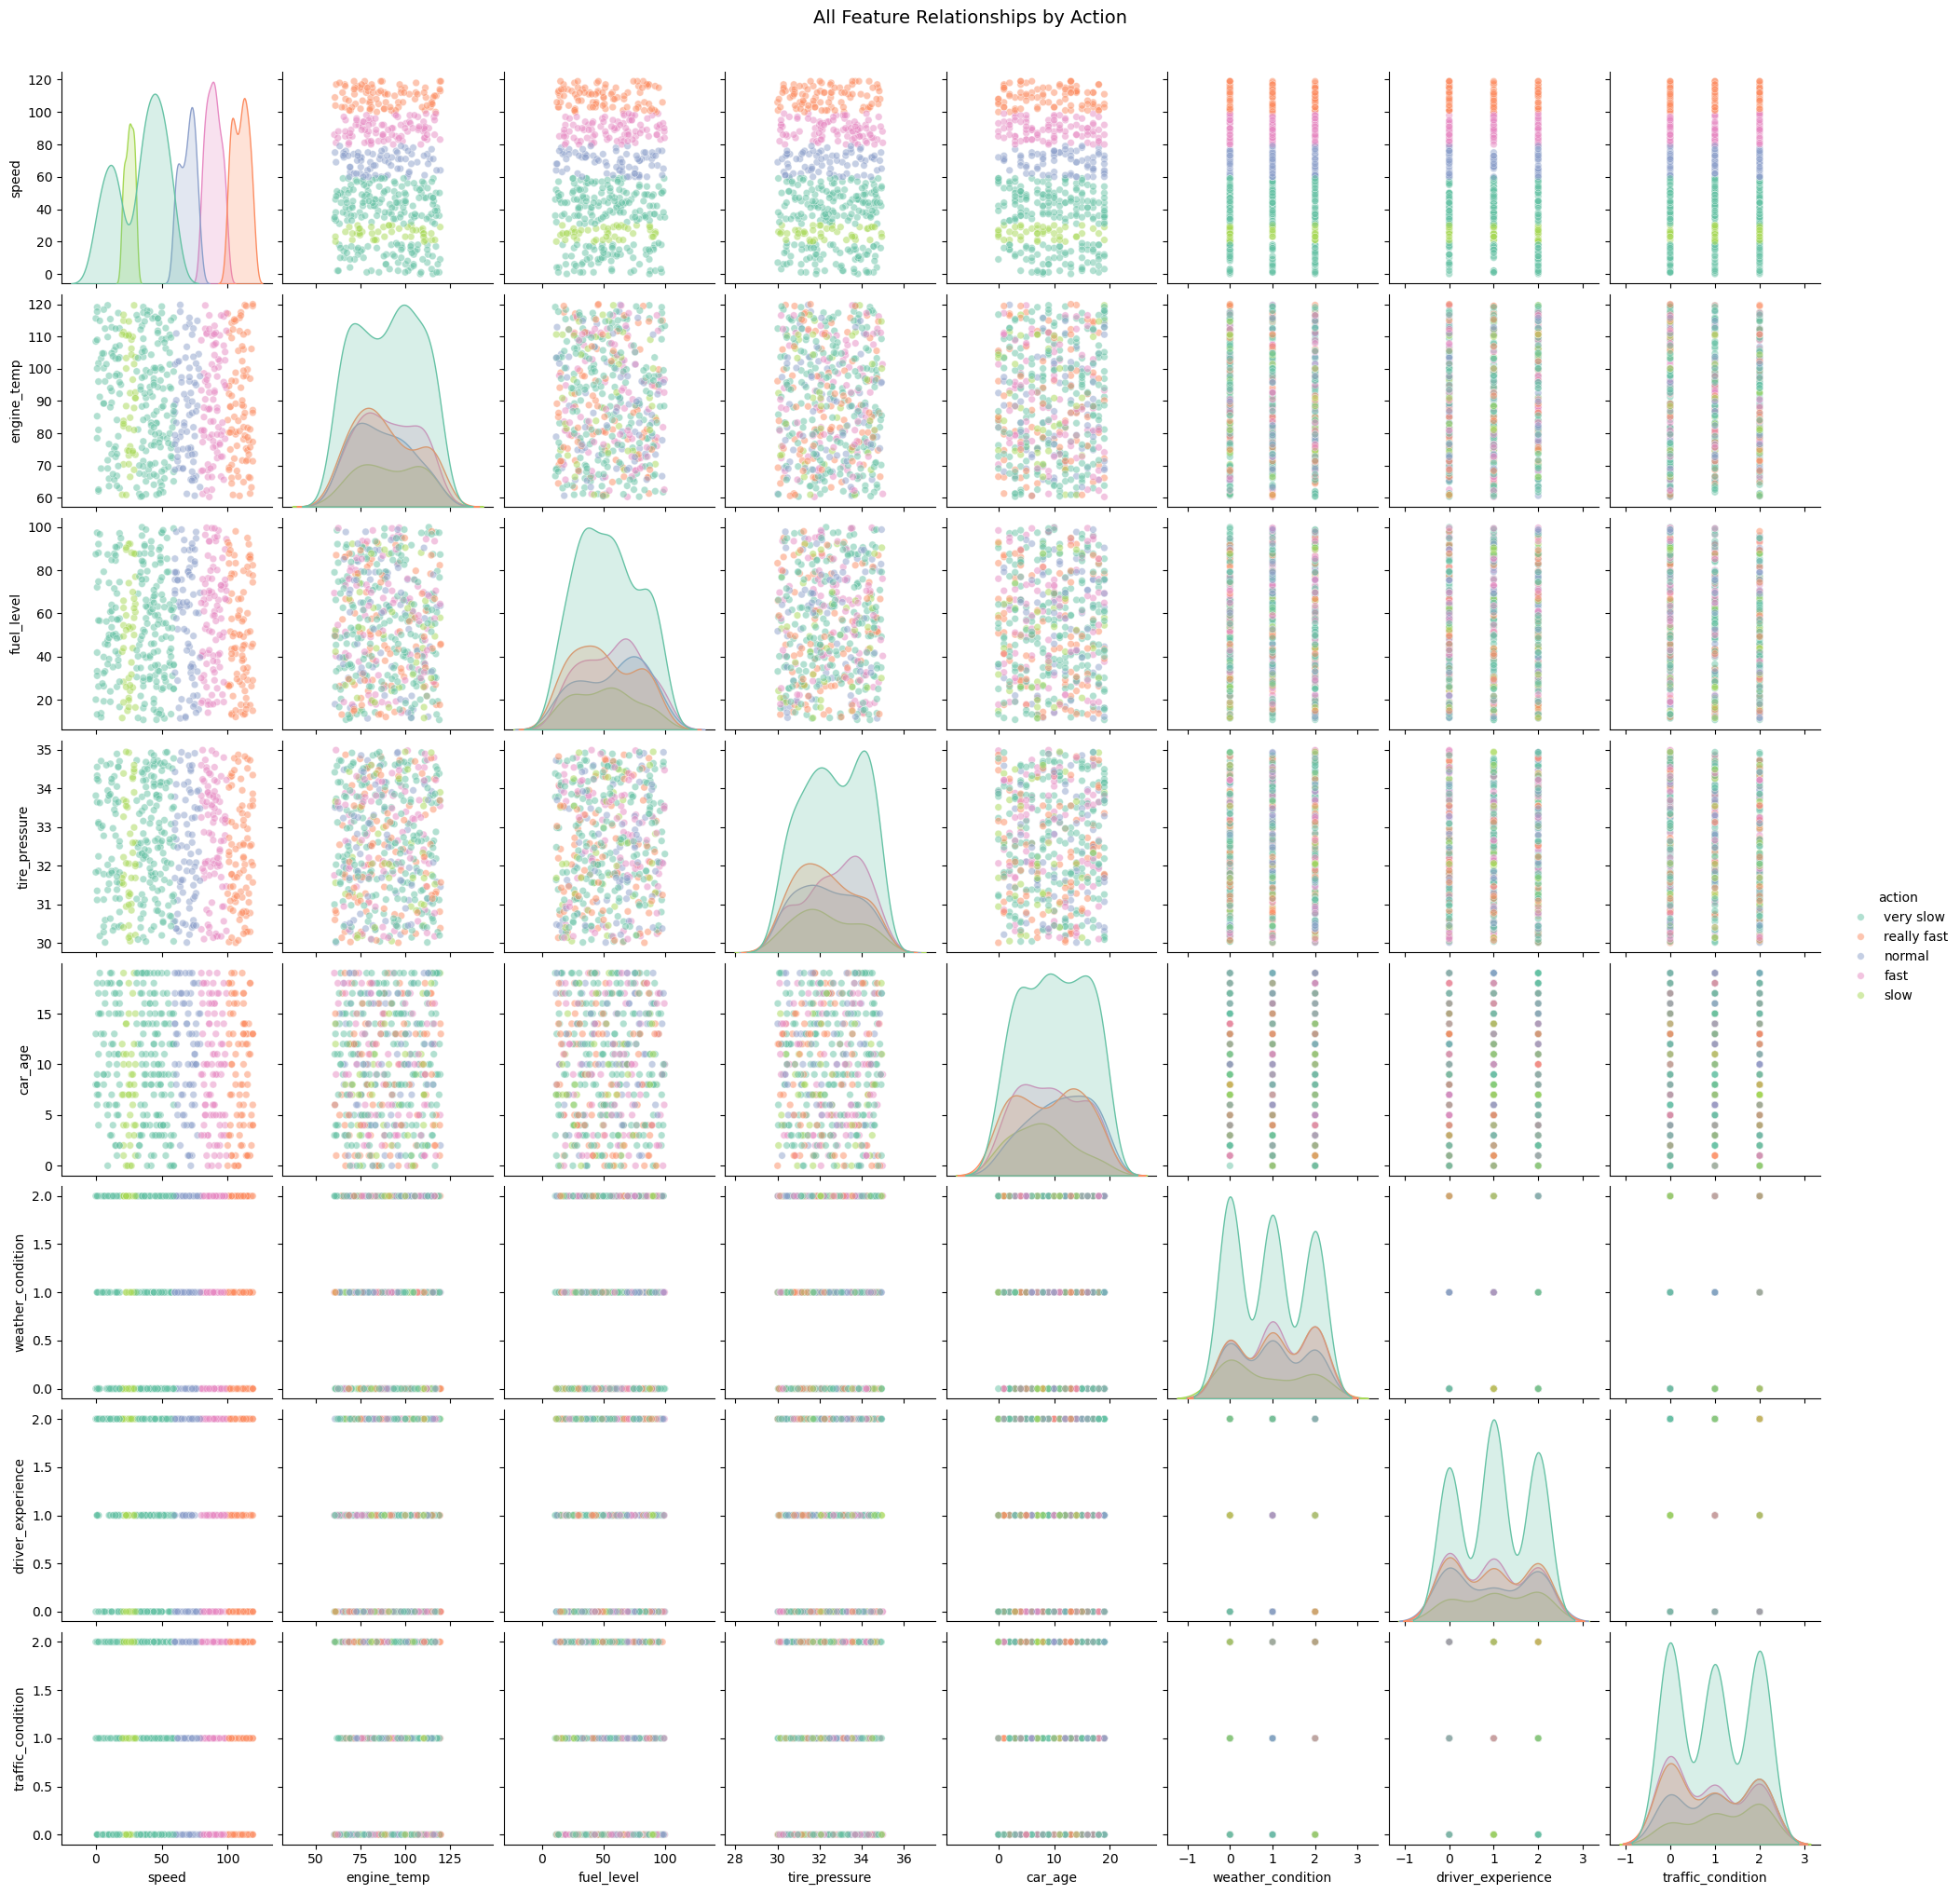

In [8]:
# pairplot to see all relationships at once
pair = sns.pairplot(df, hue='action', diag_kind='kde', palette='Set2',
                     plot_kws={'alpha': 0.5, 's': 30})
pair.figure.suptitle('All Feature Relationships by Action', y=1.02, fontsize=14)
plt.show()

## Step 4: Preparing data for the model

Alright, now I need to split the data into features (X) and target (y), then split into training and testing sets. I'll also scale the features since Decision Trees don't really need it but its good practice.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# separate features and target
X = df.drop('action', axis=1)
y = df['action']

# encode the target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 80-20 split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")
print(f"\nClasses: {le.classes_}")

Training samples: 400
Testing samples: 100

Classes: ['fast' 'normal' 'really fast' 'slow' 'very slow']


## Step 5: Training the Decision Tree

Now for the actual model. I'm using Decision Tree Classifier because it's interpretable and works well for this kind of classification problem.

In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# train the model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# predictions
y_pred = dt_model.predict(X_test)

# evaluate
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

        fast       1.00      1.00      1.00        13
      normal       1.00      1.00      1.00        11
 really fast       1.00      1.00      1.00        17
        slow       1.00      1.00      1.00        12
   very slow       1.00      1.00      1.00        47

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



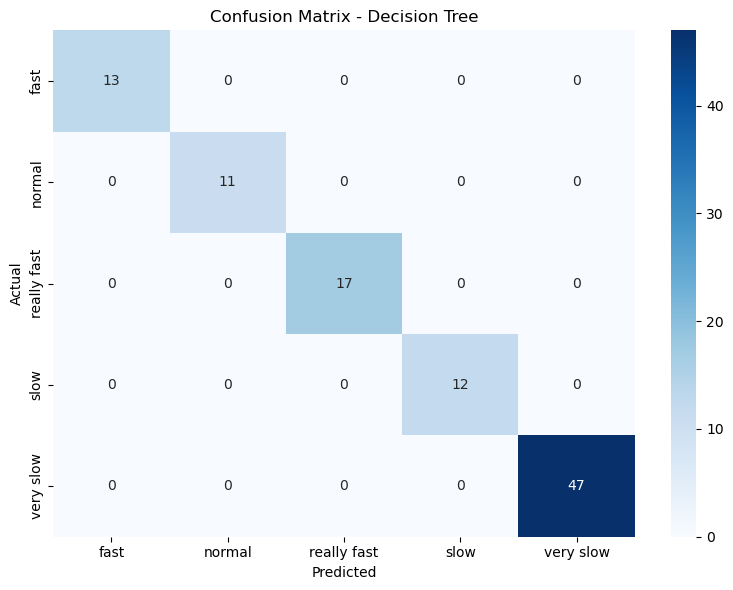

As you can see the model is doing pretty well. Most predictions are on the diagonal which means correct.


In [11]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

print("As you can see the model is doing pretty well. Most predictions are on the diagonal which means correct.")

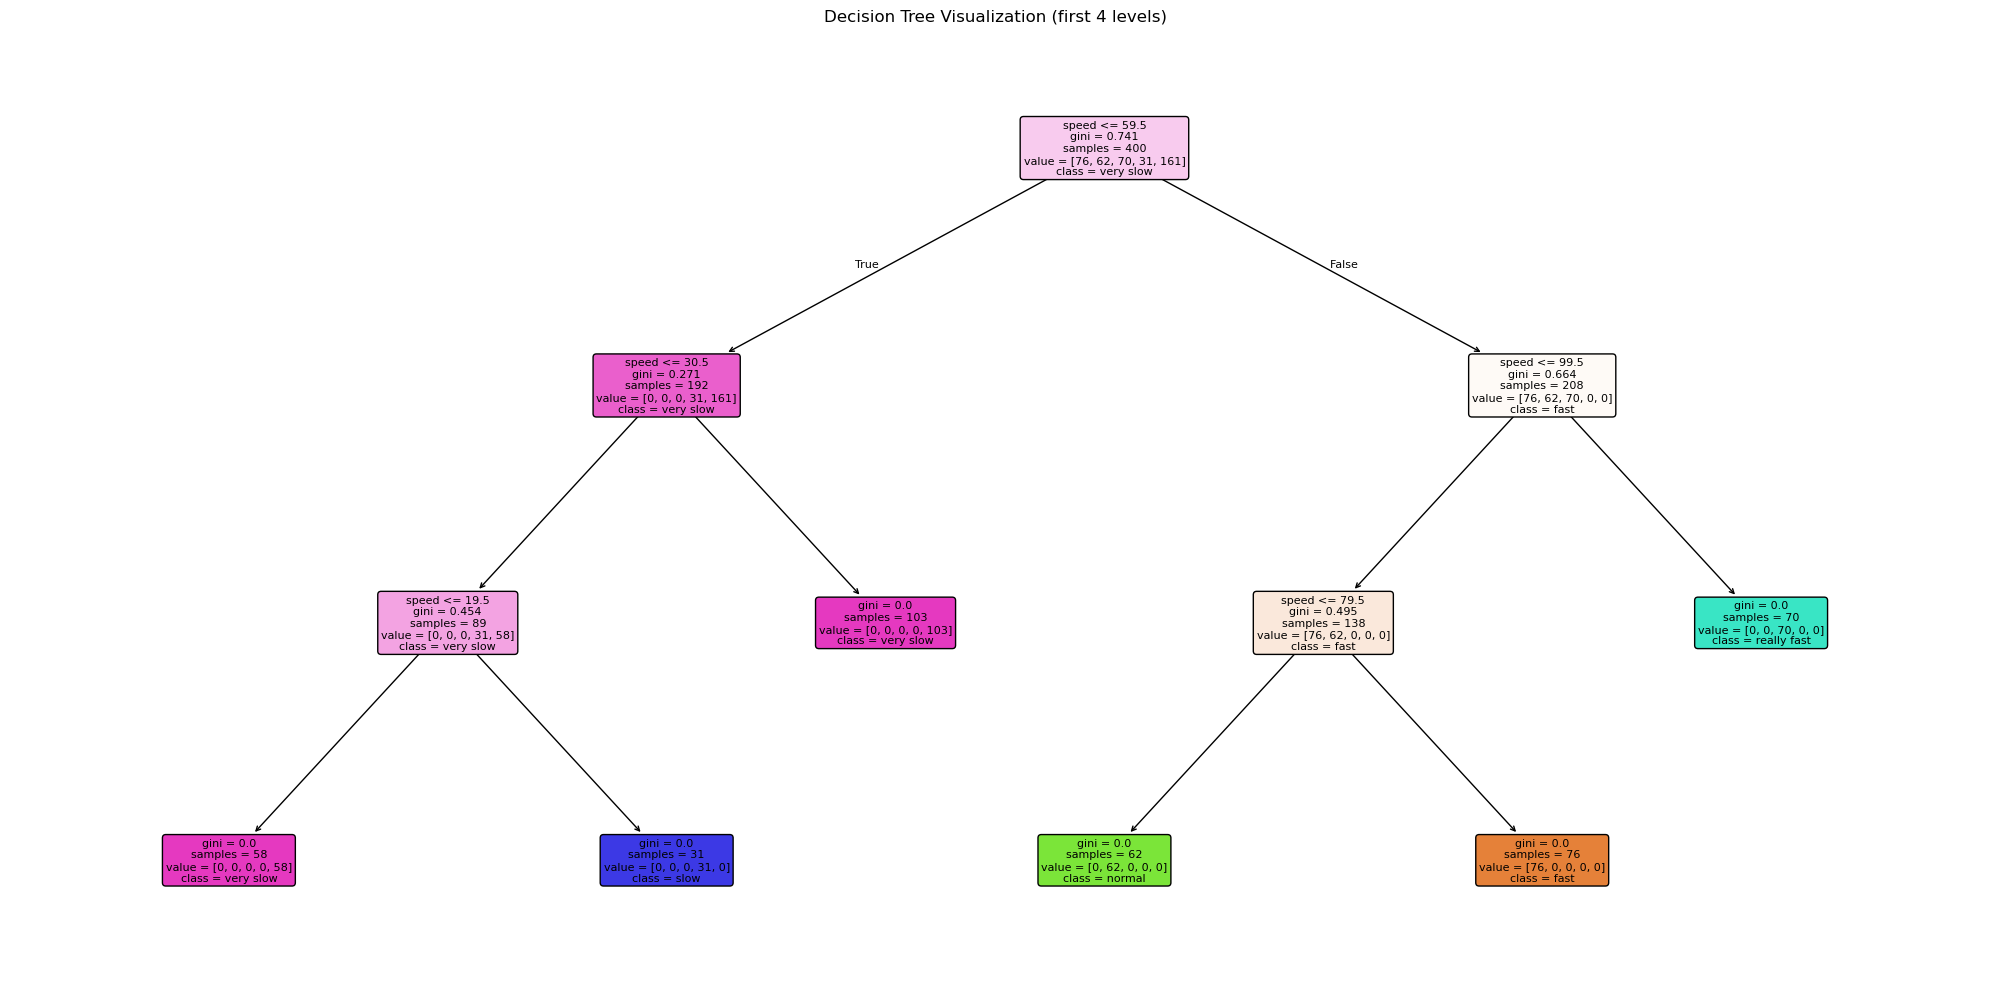

In [12]:
# lets visualize the actual decision tree
plt.figure(figsize=(20, 10))
plot_tree(dt_model, feature_names=X.columns, class_names=le.classes_,
          filled=True, rounded=True, fontsize=8, max_depth=4)
plt.title('Decision Tree Visualization (first 4 levels)')
plt.tight_layout()
plt.show()

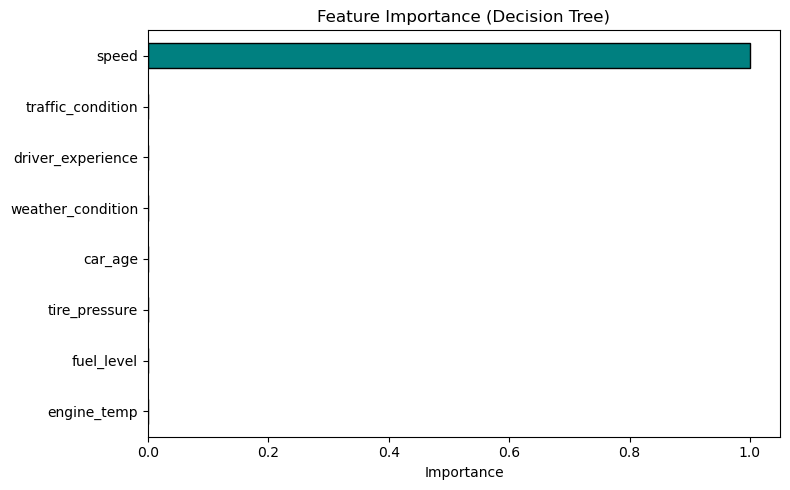

As expected, speed is by far the most important feature since the action classes are defined based on speed.
Other features like engine_temp and fuel_level contribute a little but speed dominates.


In [13]:
# feature importance - which features did the tree use the most?
importance = pd.Series(dt_model.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='teal', edgecolor='black')
plt.title('Feature Importance (Decision Tree)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print("As expected, speed is by far the most important feature since the action classes are defined based on speed.")
print("Other features like engine_temp and fuel_level contribute a little but speed dominates.")

## Step 6: Cross Validation

Just to make sure the model is not overfitting, I ran 5-fold cross validation. This basically splits the data into 5 parts and trains/tests 5 times to get a more reliable accuracy estimate.

Cross Validation Scores: [1. 1. 1. 1. 1.]
Mean Accuracy: 1.0000
Standard Deviation: 0.0000


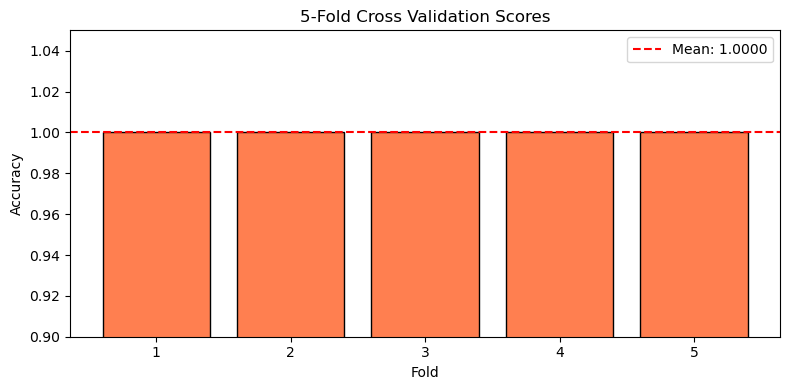

In [14]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(dt_model, X, y_encoded, cv=5, scoring='accuracy')

print(f"Cross Validation Scores: {cv_scores.round(4)}")
print(f"Mean Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

# visualize CV scores
plt.figure(figsize=(8, 4))
plt.bar(range(1, 6), cv_scores, color='coral', edgecolor='black')
plt.axhline(y=cv_scores.mean(), color='red', linestyle='--', label=f'Mean: {cv_scores.mean():.4f}')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('5-Fold Cross Validation Scores')
plt.legend()
plt.ylim(0.9, 1.05)
plt.tight_layout()
plt.show()

## Summary

So the Decision Tree is doing really well on this dataset. The accuracy is high and the cross validation confirms it's not just overfitting.

**What I learned:**
- Speed is obviously the most important feature for determining the action
- The other features (engine temp, fuel level, etc.) don't contribute much since the classes are defined by speed
- Decision Trees are nice because you can actually visualize the decision process

**Next steps (in V1.1):**
- Try multiple models and compare them
- Do hyperparameter tuning
- Add more detailed visualizations